# 03 – Regression
**Practicals 7–11:** simple, multiple and polynomial regression, MAE / MSE / R² comparison, and the cost function.

In [1]:
import sys, warnings
from pathlib import Path

sys.path.append(str(Path.cwd().parent))   # lets us import from the src/ folder
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
from src.preprocessing import load_clean_data, get_regression_data, split_data
from src.regression import (build_simple, build_multiple, build_polynomial,
                            compare_models, final_test_score, mse_cost, gradient_descent)

df = load_clean_data()
X, y = get_regression_data(df)
X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y)
print("Train / validation / test rows:", len(X_train), len(X_val), len(X_test))

Train / validation / test rows: 123 26 27


## Practicals 7–10 – Simple, multiple and polynomial regression
All three models are trained on the training set and compared on the validation set with MAE, MSE and R².

In [2]:
models = {
    "Simple": build_simple(),
    "Multiple": build_multiple(),
    "Polynomial (deg 2)": build_polynomial(2),
}
results = compare_models(models, X_train, y_train, X_val, y_val)
results

,Model,MAE,MSE,R2
0,Simple,16.044,379.187,0.434
1,Multiple,11.549,176.596,0.737
2,Polynomial (deg 2),11.775,182.471,0.728


### Practical 7 – Simple regression line

plates_eaten = 38.02 + 0.595 x students_registered


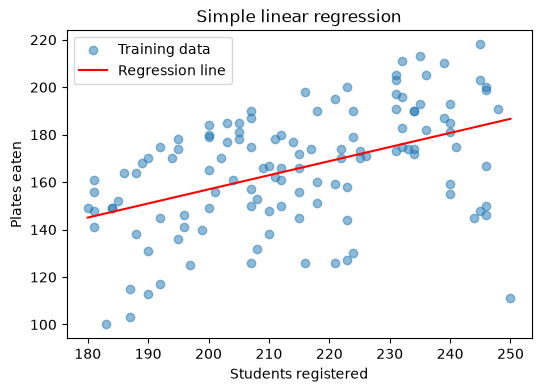

In [3]:
simple = models["Simple"]
coef = simple.named_steps["reg"].coef_[0]
intercept = simple.named_steps["reg"].intercept_
print(f"plates_eaten = {intercept:.2f} + {coef:.3f} x students_registered")

xs = np.linspace(X_train["students_registered"].min(), X_train["students_registered"].max(), 100)
line = simple.predict(pd.DataFrame({"students_registered": xs}))

plt.figure(figsize=(6, 4))
plt.scatter(X_train["students_registered"], y_train, alpha=0.5, label="Training data")
plt.plot(xs, line, color="red", label="Regression line")
plt.xlabel("Students registered"); plt.ylabel("Plates eaten")
plt.title("Simple linear regression"); plt.legend()
plt.savefig(FIG_DIR / "p7_simple_regression.png", dpi=120)
plt.show()

### Practical 8 – What did the multiple regression learn?

In [4]:
multiple = models["Multiple"]
names = multiple.named_steps["prep"].get_feature_names_out()
coefs = multiple.named_steps["reg"].coef_
(pd.DataFrame({"feature": names, "coefficient": coefs})
   .assign(size=lambda d: d.coefficient.abs())
   .sort_values("size", ascending=False)
   .drop(columns="size").head(10).round(2))

,feature,coefficient
23,remainder__holiday_or_event,-44.28
3,cat__day_of_week_Sunday,-21.67
22,remainder__exam_week,-12.99
20,cat__menu_main_Upma,-8.84
1,cat__day_of_week_Monday,7.46
0,cat__day_of_week_Friday,5.73
18,cat__menu_main_Rajma,5.66
12,cat__menu_main_Idli,5.47
6,cat__day_of_week_Wednesday,4.20
17,cat__menu_main_Poha,3.29


### Final test score
The test set is used **once**: train on train + validation, then score on the test set.

In [5]:
test_scores = final_test_score(build_multiple(), X_train, y_train, X_val, y_val, X_test, y_test)
print("Test rows:", len(y_test))
{k: round(v, 3) for k, v in test_scores.items()}

Test rows: 27


{'MAE': 7.179, 'MSE': 68.785, 'R2': 0.767}

## Practical 11 – Cost function
The cost J(w, b) is the mean squared error of the line y = w·x + b. We plot it against the slope, then watch gradient descent find the minimum.

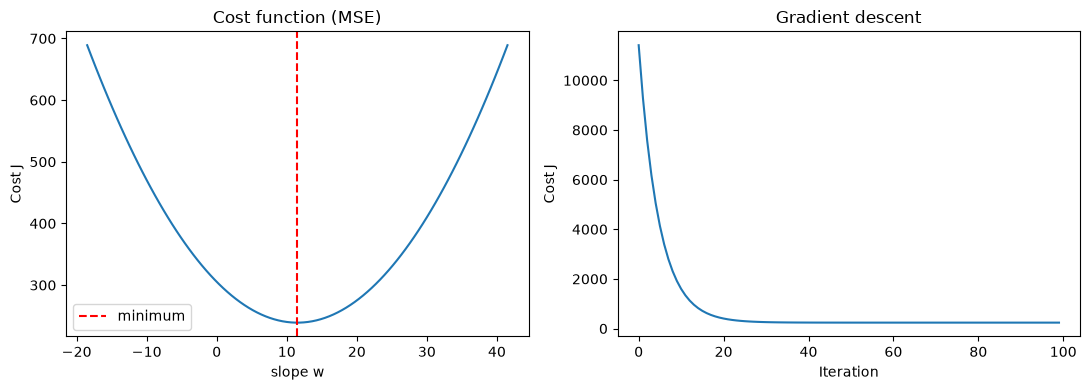

Gradient descent: w=11.51, b=165.73 | Closed form: w=11.51, b=165.73


In [6]:
x = X_train["students_registered"].values
y_arr = y_train.values
xs_std = (x - x.mean()) / x.std()          # standardize so gradient descent is stable

w_best, b_best = np.polyfit(xs_std, y_arr, 1)   # closed-form best fit
ws = np.linspace(w_best - 30, w_best + 30, 100)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ws, [mse_cost(w, b_best, xs_std, y_arr) for w in ws])
axes[0].axvline(w_best, color="red", linestyle="--", label="minimum")
axes[0].set_xlabel("slope w"); axes[0].set_ylabel("Cost J")
axes[0].set_title("Cost function (MSE)"); axes[0].legend()

w, b, history = gradient_descent(xs_std, y_arr, lr=0.1, iterations=100)
axes[1].plot(history)
axes[1].set_xlabel("Iteration"); axes[1].set_ylabel("Cost J")
axes[1].set_title("Gradient descent")

plt.tight_layout()
plt.savefig(FIG_DIR / "p11_cost_function.png", dpi=120)
plt.show()
print(f"Gradient descent: w={w:.2f}, b={b:.2f} | Closed form: w={w_best:.2f}, b={b_best:.2f}")